<a href="https://colab.research.google.com/github/novalrnv/machine_learning/blob/main/JS07/JS07-Tugas1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS07 - Klasterisasi
## Tugas Lab - Klasterisasi Data Nasabah Kartu Kredit

Dataset: data nasabah kartu kredit (download dari modul, taruh satu folder dengan notebook ini).

**Daftar soal:**
1. Scatterplot `Avg_Credit_Limit` vs `Total_credit_card`, apakah sebaran linier?
2. Model K-Means + elbow method (linechart + analisis)
3. Scatterplot hasil klasterisasi K-Means
4. Model DBSCAN dengan seluruh variabel yang dapat digunakan
5. Penentuan parameter terbaik DBSCAN dengan elbow method (linechart + analisis)
6. Silhouette score dan DBI dari model DBSCAN

## Langkah 0 - Import Library

In [2]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

## Langkah 1 - Load dan Inspeksi Data

In [3]:
DATA_PATH = '/content/CC_Customer_Dataset.csv'

try:
    df = pd.read_csv(DATA_PATH)
except FileNotFoundError:

    found = [f for f in glob.glob('*.csv') if 'credit' in f.lower()]
    print('File tidak ditemukan, kandidat:', found)
    df = pd.read_csv(found[0])

df.head()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


In [5]:
df.describe()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
count,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000
mean,330.500000,55141.443939,34574.242424,4.706061,2.403030,2.606061,3.583333
std,190.669872,25627.772200,37625.487804,2.167835,1.631813,2.935724,2.865317
min,1.000000,11265.000000,3000.000000,1.000000,0.000000,0.000000,0.000000
25%,165.750000,33825.250000,10000.000000,3.000000,1.000000,1.000000,1.000000
50%,330.500000,53874.500000,18000.000000,5.000000,2.000000,2.000000,3.000000
75%,495.250000,77202.500000,48000.000000,6.000000,4.000000,4.000000,5.000000
max,660.000000,99843.000000,200000.000000,10.000000,5.000000,15.000000,10.000000


In [6]:
def find_col(keyword):
    for col in df.columns:
        if keyword.lower() in col.lower():
            return col
    raise KeyError(f'Kolom dengan kata "{keyword}" tidak ditemukan: {list(df.columns)}')

COL_LIMIT = find_col('limit')           # Avg_Credit_Limit
COL_CARDS = find_col('credit_card')     # Total_credit_card / Total_Credit_Cards
print(COL_LIMIT, '|', COL_CARDS)

Avg_Credit_Limit | Total_Credit_Cards


## Soal 1 - Scatterplot Avg_Credit_Limit vs Total_credit_card

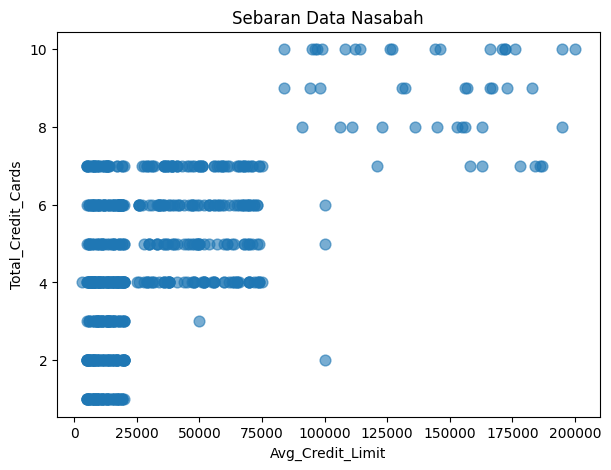

In [7]:
plt.figure(figsize=(7, 5))
plt.scatter(df[COL_LIMIT], df[COL_CARDS], s=60, alpha=0.6)
plt.xlabel(COL_LIMIT)
plt.ylabel(COL_CARDS)
plt.title('Sebaran Data Nasabah')
plt.show()

**Analisis Soal 1:**

Sebaran data tidak linier. Titik-titik tidak membentuk garis lurus, tapi mengelompok. Data dengan limit kredit rendah dan menengah menumpuk padat, sedangkan data dengan limit tinggi (di atas 85.000) lebih jarang dan terpisah dari kelompok lainnya. Jumlah kartu juga bernilai bulat (1 sampai 10), jadi titiknya membentuk barisan horizontal. Karena polanya berupa kelompok, bukan garis, data ini cocok untuk diklasterisasi.

## Soal 2 - K-Means dan Elbow Method

Fitur yang dipakai adalah dua variabel pada Soal 1. Karena skala `Avg_Credit_Limit` (puluhan ribu) jauh lebih besar dari `Total_credit_card` (satuan), data distandarisasi dulu agar K-Means tidak didominasi satu fitur.

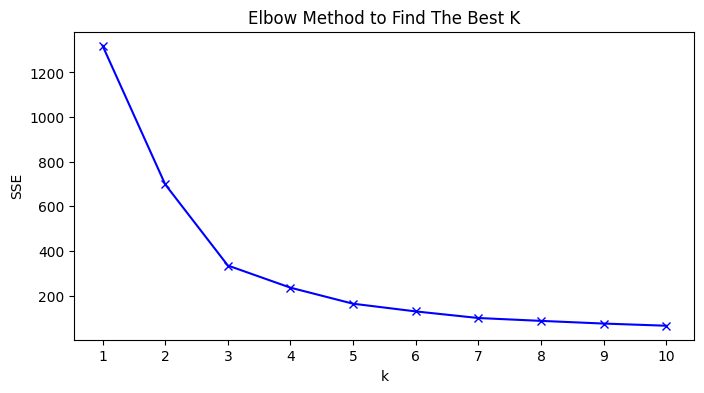

In [8]:
X2 = df[[COL_LIMIT, COL_CARDS]]
X2_scaled = StandardScaler().fit_transform(X2)

sse = []
K = range(1, 11)
for k in K:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X2_scaled)
    sse.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K, sse, 'bx-')
plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Elbow Method to Find The Best K')
plt.xticks(list(K))
plt.show()

**Analisis Soal 2:**

Berdasarkan grafik elbow, nilai k terbaik adalah 3. Dari k=1 ke k=2 dan dari k=2 ke k=3, nilai SSE turun tajam (sekitar 1300 → 700 → 330). Setelah k=3, penurunannya melandai dan stabil. Titik tekukan inilah yang disebut “elbow”. Nilai k yang lebih besar (misalnya 8 atau 10) memang punya SSE lebih rendah, tapi itu terjadi karena cluster makin kecil dan sempit, bukan berarti modelnya lebih baik. Selain itu, k=3 sesuai dengan pola yang terlihat di scatterplot Soal 1, yaitu tiga kelompok (limit rendah, menengah, dan tinggi).

## Soal 3 - Scatterplot Hasil K-Means

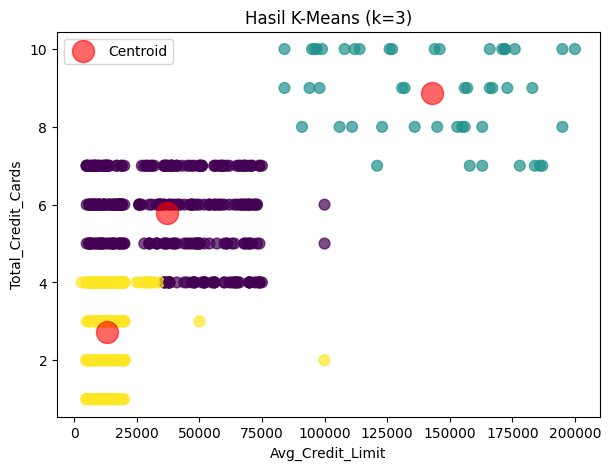

Nilai SSE: 334.72447276058625


In [9]:
# Isi K_BEST sesuai hasil elbow pada Soal 2
K_BEST = 3

kmeans = KMeans(n_clusters=K_BEST, n_init=10, random_state=42)
labels_km = kmeans.fit_predict(X2_scaled)

plt.figure(figsize=(7, 5))
plt.scatter(df[COL_LIMIT], df[COL_CARDS], c=labels_km, s=60, cmap='viridis', alpha=0.7)

# centroid dikembalikan ke skala asli
centers = StandardScaler().fit(X2).inverse_transform(kmeans.cluster_centers_)
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=250, alpha=0.6, label='Centroid')

plt.xlabel(COL_LIMIT)
plt.ylabel(COL_CARDS)
plt.title(f'Hasil K-Means (k={K_BEST})')
plt.legend()
plt.show()

print(f'Nilai SSE: {kmeans.inertia_}')

**Analisis Soal 3:**

Model K-Means dengan k=3 membagi nasabah menjadi tiga cluster:

- Cluster kuning (limit rendah): limit kredit sekitar 5.000 sampai 20.000 dengan jumlah kartu sedikit (1 sampai 4). Centroid-nya kira-kira di limit 13.000 dan 3 kartu.
- Cluster ungu (limit menengah): limit kredit sekitar 25.000 sampai 75.000 dengan jumlah kartu 4 sampai 7. Centroid-nya kira-kira di limit 37.000 dan 6 kartu.
- Cluster hijau (limit tinggi): limit kredit di atas 85.000 dengan jumlah kartu banyak (7 sampai 10). Centroid-nya kira-kira di limit 143.000 dan 9 kartu.

## Soal 4 - DBSCAN dengan Seluruh Variabel yang Dapat Digunakan

Kolom identitas (nomor urut / customer key) tidak dipakai karena hanya penanda, bukan fitur. Semua kolom numerik sisanya dipakai, lalu distandarisasi karena DBSCAN berbasis jarak.

In [10]:
# Buang kolom identitas (nama mengandung 'sl_no', 'key', atau 'id')
id_cols = [c for c in df.columns
           if any(w in c.lower() for w in ['sl_no', 'key', 'id'])]
print('Kolom identitas yang dibuang:', id_cols)

X_all = df.drop(columns=id_cols).select_dtypes(include='number')
print('Fitur yang dipakai:', list(X_all.columns))

X_all_scaled = StandardScaler().fit_transform(X_all)
X_all_scaled.shape

Kolom identitas yang dibuang: ['Sl_No', 'Customer Key']
Fitur yang dipakai: ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']


(660, 5)

## Soal 5 - Menentukan Parameter Terbaik DBSCAN dengan Elbow Method

Pada DBSCAN tidak ada parameter `k`. Elbow method dipakai untuk menentukan **epsilon (eps)** melalui grafik *k-distance*:

1. Tentukan `min_samples` (aturan umum: 2 x jumlah fitur).
2. Hitung jarak tiap titik ke tetangga ke-`min_samples`.
3. Urutkan jarak lalu plot. Titik "elbow" (tekukan tajam) adalah kandidat eps.

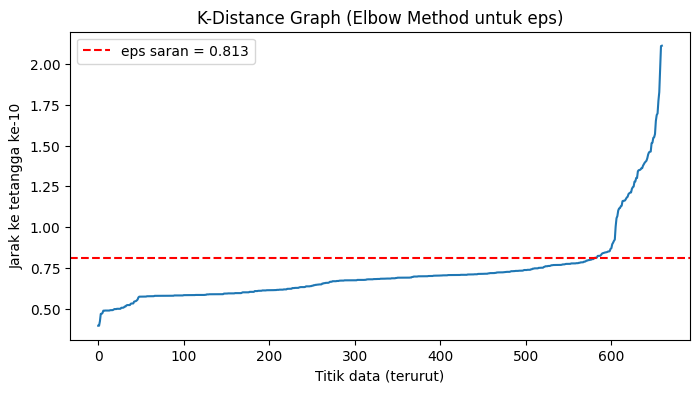

min_samples = 10, eps saran = 0.813


In [11]:
MIN_SAMPLES = 2 * X_all_scaled.shape[1]

nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X_all_scaled)
distances, _ = nn.kneighbors(X_all_scaled)
k_dist = np.sort(distances[:, -1])

# estimasi otomatis titik elbow: titik terjauh dari garis lurus awal-akhir kurva
x = np.arange(len(k_dist))
p1 = np.array([0, k_dist[0]])
p2 = np.array([len(k_dist) - 1, k_dist[-1]])
pts = np.column_stack([x, k_dist])
v = p2 - p1
w = pts - p1
d = np.abs(v[0] * w[:, 1] - v[1] * w[:, 0]) / np.linalg.norm(v)
elbow_idx = int(np.argmax(d))
eps_suggest = k_dist[elbow_idx]

plt.figure(figsize=(8, 4))
plt.plot(k_dist)
plt.axhline(eps_suggest, color='red', linestyle='--', label=f'eps saran = {eps_suggest:.3f}')
plt.xlabel('Titik data (terurut)')
plt.ylabel(f'Jarak ke tetangga ke-{MIN_SAMPLES}')
plt.title('K-Distance Graph (Elbow Method untuk eps)')
plt.legend()
plt.show()

print(f'min_samples = {MIN_SAMPLES}, eps saran = {eps_suggest:.3f}')

**Analisis Soal 5:**

Parameter DBSCAN ditentukan dengan k-distance graph menggunakan min_samples = 10 (2 x jumlah fitur). Pada grafik, jarak ke tetangga ke-10 naik landai di kisaran 0.4 sampai 0.8, lalu melonjak tajam setelah sekitar 0.8. Titik tekukan (elbow) ini menjadi nilai eps = 0.813. Titik di bawah eps berada di area padat (anggota cluster), sedangkan titik di atasnya berada di area jarang (kandidat noise).

Namun, dengan min_samples = 10 dan eps = 0.813, DBSCAN hanya menghasilkan 1 cluster sehingga silhouette score dan DBI tidak dapat dihitung. Oleh karena itu dilakukan percobaan beberapa kombinasi min_samples dan eps, dan kombinasi terbaik adalah min_samples = 5 dan eps = 0.8, yang menghasilkan 2 cluster dengan noise 6.7% dan silhouette score positif (0.49).

In [16]:
MIN_SAMPLES = 5
EPS = 0.8

dbscan = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES)
labels_db = dbscan.fit_predict(X_all_scaled)

n_clusters = len(set(labels_db)) - (1 if -1 in labels_db else 0)
n_noise = int(np.sum(labels_db == -1))
print(f'Jumlah cluster : {n_clusters}')
print(f'Jumlah noise   : {n_noise} ({n_noise / len(labels_db):.1%})')

Jumlah cluster : 2
Jumlah noise   : 44 (6.7%)


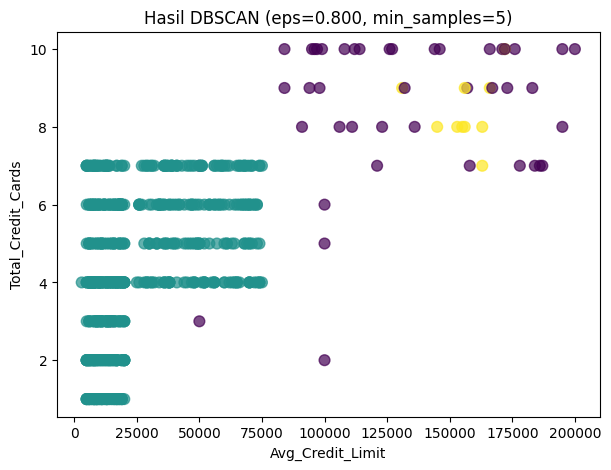

In [17]:
# Visualisasi (dua variabel pada Soal 1, warna = cluster DBSCAN; -1 = noise)
plt.figure(figsize=(7, 5))
plt.scatter(df[COL_LIMIT], df[COL_CARDS], c=labels_db, s=60, cmap='viridis', alpha=0.7)
plt.xlabel(COL_LIMIT)
plt.ylabel(COL_CARDS)
plt.title(f'Hasil DBSCAN (eps={EPS:.3f}, min_samples={MIN_SAMPLES})')
plt.show()

In [18]:
hasil = []
for ms in [5, 8, 10]:
    for eps in [0.4, 0.5, 0.6, 0.7, 0.8]:
        lbl = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_all_scaled)
        n_cl = len(set(lbl)) - (1 if -1 in lbl else 0)
        noise = np.mean(lbl == -1)
        if n_cl >= 2:
            sil = silhouette_score(X_all_scaled, lbl)
            dbi = davies_bouldin_score(X_all_scaled, lbl)
        else:
            sil, dbi = np.nan, np.nan
        hasil.append([ms, eps, n_cl, f'{noise:.1%}', sil, dbi])

pd.DataFrame(hasil, columns=['min_samples', 'eps', 'n_cluster', 'noise', 'silhouette', 'DBI'])

,min_samples,eps,n_cluster,noise,silhouette,DBI
0,5,0.4,25,72.3%,-0.302580,1.605426
1,5,0.5,24,31.1%,-0.140309,1.859209
2,5,0.6,8,12.4%,-0.008689,2.163947
3,5,0.7,1,8.8%,NaN,NaN
4,5,0.8,2,6.7%,0.489531,2.034903
5,8,0.4,2,97.1%,-0.354282,1.302901
6,8,0.5,18,65.6%,-0.260383,1.782910
7,8,0.6,12,24.5%,-0.035510,2.189458
8,8,0.7,1,9.7%,NaN,NaN
9,8,0.8,1,8.2%,NaN,NaN


**Analisis**

Model DBSCAN dibuat menggunakan seluruh variabel yang dapat digunakan, yaitu 5 fitur numerik: Avg_Credit_Limit, Total_Credit_Cards, Total_visits_bank, Total_visits_online, dan Total_calls_made. Kolom Sl_No dan Customer Key tidak dipakai karena hanya penanda identitas. Data distandarisasi dengan StandardScaler karena DBSCAN berbasis jarak.

Dengan eps = 0.8 dan min_samples = 5, model menghasilkan 2 cluster dan 44 data noise (6.7%). Cluster pertama berisi mayoritas nasabah dengan limit rendah sampai menengah, sedangkan cluster kedua berisi sekelompok kecil nasabah dengan limit tinggi. Nasabah limit tinggi lainnya yang tersebar dianggap noise.

## Soal 6 - Silhouette Score dan DBI Model DBSCAN

In [19]:
if n_clusters >= 2:
    print(f'Silhouette Score     : {silhouette_score(X_all_scaled, labels_db)}')
    print(f'Davies-Bouldin Index : {davies_bouldin_score(X_all_scaled, labels_db)}')
else:
    print('DBSCAN hanya menghasilkan < 2 cluster, metrik tidak bisa dihitung.')
    print('Coba ubah EPS (naikkan/turunkan) pada sel sebelumnya.')

Silhouette Score     : 0.4895311742531093
Davies-Bouldin Index : 2.034903473268468


**Analisis Soal 6:**

Model DBSCAN (eps = 0.8, min_samples = 5) menghasilkan Silhouette Score = 0.490 dan Davies-Bouldin Index = 2.035. Silhouette score tergolong cukup baik karena positif dan mendekati 0.5, artinya sebagian besar data lebih dekat ke clusternya sendiri dibanding cluster lain. Namun DBI masih relatif tinggi (makin kecil makin baik), artinya pemisahan antar cluster belum optimal. Perlu diingat bahwa noise (label -1) ikut dihitung sebagai satu kelompok pada kedua metrik, dan silhouette kurang cocok untuk cluster yang bentuknya tidak linier. Karena itu hasil ini dilengkapi dengan persentase noise yang kecil (6.7%) dan inspeksi visual pada scatterplot.